In [1]:
import sys

print("Python utilisé :", sys.executable)
print("Version Python :", sys.version)

Python utilisé : c:\Users\pc\Desktop\tp3PROMPT\.venv\Scripts\python.exe
Version Python : 3.11.15 (main, May 10 2026, 19:31:25) [MSC v.1944 64 bit (AMD64)]


In [2]:

import pandas as pd

print("Version de Pandas :", pd.__version__)


Version de Pandas : 2.2.3


In [3]:
import pandas as pd

# Charger le dataset CSV
df = pd.read_csv("data/dataset.csv")

# Afficher les 5 premières lignes
display(df.head())


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:

print("Dimensions :", df.shape)
print("Colonnes :", df.columns.tolist())


Dimensions : (50000, 2)
Colonnes : ['review', 'sentiment']


In [5]:

# Afficher le nom des colonnes
print("Colonnes :", df.columns.tolist())

# Afficher le nombre total d'avis
print("Nombre total d'avis :", len(df))

# Afficher la répartition des classes
print("\nRépartition des classes :")
print(df.iloc[:, 1].value_counts(dropna=False))


Colonnes : ['review', 'sentiment']
Nombre total d'avis : 50000

Répartition des classes :
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [6]:

print("Valeurs manquantes par colonne :")
print(df.isnull().sum())


Valeurs manquantes par colonne :
review       0
sentiment    0
dtype: int64


In [7]:

df = df.rename(columns={"review": "text"})

print(df.columns.tolist())


['text', 'sentiment']


In [8]:

from sklearn.model_selection import train_test_split

examples_df, gold_examples_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["sentiment"]
)

print("Nombre d'exemples :", len(examples_df))
print("Nombre de gold examples :", len(gold_examples_df))


Nombre d'exemples : 40000
Nombre de gold examples : 10000


In [9]:

print("Répartition dans examples_df :")
print(examples_df["sentiment"].value_counts())

print("\nRépartition dans gold_examples_df :")
print(gold_examples_df["sentiment"].value_counts())


Répartition dans examples_df :
sentiment
positive    20000
negative    20000
Name: count, dtype: int64

Répartition dans gold_examples_df :
sentiment
negative    5000
positive    5000
Name: count, dtype: int64


In [10]:

# Sélectionner 20 exemples de référence
gold_sample_df = gold_examples_df.sample(
    n=20,
    random_state=42
)

# Afficher le nombre d'exemples sélectionnés
print("Nombre de Gold Examples :", len(gold_sample_df))

# Afficher les 5 premiers avis sélectionnés
display(gold_sample_df.head())


Nombre de Gold Examples : 20


,text,sentiment
44114,This is loosely based on the ideas of the orig...,negative
38347,"This movie was on British TV last night, and i...",positive
32006,"What a dreadful movie. The effects were poor, ...",negative
19369,"I'll keep this short, as I know I don't need t...",negative
22208,I don't know what the rest of you guys watch S...,negative


In [11]:

print("Répartition des 20 Gold Examples :")
print(gold_sample_df["sentiment"].value_counts())


Répartition des 20 Gold Examples :
sentiment
negative    11
positive     9
Name: count, dtype: int64


In [12]:

from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="llama3.2:3b",
    temperature=0
)


In [13]:

zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'.

Movie reviews will be delimited by triple backticks in the input.

Answer only 'positive' or 'negative'.
Do not explain your answer.
"""

zero_shot_prompt = [
    {
        "role": "system",
        "content": zero_shot_system_message
    }
]


In [14]:

# Sélectionner le premier avis des Gold Examples
review = gold_sample_df.iloc[0]["text"]

# Récupérer son véritable sentiment
true_sentiment = gold_sample_df.iloc[0]["sentiment"]

print("Avis :", review)
print("\nVrai sentiment :", true_sentiment)


Avis : This is loosely based on the ideas of the original 80's hit . It's set in the modern day as we see a base in Afghanistan get destroyed by a UAV right at the start.<br /><br />And that's exactly where the movie jumps the shark. UAV's aren't armed. They could be but I don't think it's ever been tried for real. We get to see the computer that has masterminded this operation, called R.I.P.L.E.Y. We are introduced to "hacker" Will Farmer (he's good at chemistry & electronics which doesn't make him a computer hacker) & his love interest, Annie) & Will's 1st attempt at hacking is not only a complete failure his IP address is also logged and Annie guessed who it was. We also meet Wills mom who works for a chemical company.<br /><br />Wills taking money from his neighbours bank account (Mr Massude) isn't a hack (he helped him set up the account), we then get a nod back to the original movie where they decide against playing Global Thermonuclear War & they play The Dead Code. The trace th

In [15]:

user_message = {
    "role": "user",
    "content": f"Classify this movie review:\n```{review}```"
}

response = llm.invoke(
    zero_shot_prompt + [user_message]
)

prediction = response.content.strip().lower()

print("Prédiction du LLM :", prediction)
print("Vrai sentiment :", true_sentiment)
print("Prédiction correcte :", prediction == true_sentiment)


Prédiction du LLM : negative
Vrai sentiment : negative
Prédiction correcte : True


In [16]:

# Listes pour stocker les résultats
predictions = []
ground_truths = []

# Parcourir les 20 avis
for i, (_, row) in enumerate(gold_sample_df.iterrows(), start=1):

    # Récupérer l'avis et sa vraie classe
    review = row["text"]
    true_sentiment = row["sentiment"]

    # Construire le message utilisateur
    user_message = {
        "role": "user",
        "content": f"Classify this movie review:\n```{review}```"
    }

    # Interroger Llama 3.2
    response = llm.invoke(
        zero_shot_prompt + [user_message]
    )

    # Récupérer la prédiction
    prediction = response.content.strip().lower()

    # Vérifier le format de la réponse
    if prediction not in ["positive", "negative"]:
        prediction = "unknown"

    # Enregistrer les résultats
    predictions.append(prediction)
    ground_truths.append(true_sentiment)

    print(f"Avis {i}/20 : {prediction} | Réel : {true_sentiment}")


Avis 1/20 : negative | Réel : negative
Avis 2/20 : positive | Réel : positive
Avis 3/20 : negative | Réel : negative
Avis 4/20 : negative | Réel : negative
Avis 5/20 : positive | Réel : negative
Avis 6/20 : negative | Réel : negative
Avis 7/20 : negative | Réel : negative
Avis 8/20 : positive | Réel : positive
Avis 9/20 : negative | Réel : negative
Avis 10/20 : positive | Réel : positive
Avis 11/20 : positive | Réel : positive
Avis 12/20 : negative | Réel : negative
Avis 13/20 : negative | Réel : negative
Avis 14/20 : negative | Réel : negative
Avis 15/20 : positive | Réel : positive
Avis 16/20 : positive | Réel : positive
Avis 17/20 : positive | Réel : positive
Avis 18/20 : positive | Réel : positive
Avis 19/20 : positive | Réel : positive
Avis 20/20 : negative | Réel : negative


In [17]:

results_df = pd.DataFrame({
    "Vrai sentiment": ground_truths,
    "Prédiction LLM": predictions
})

results_df["Correct"] = (
    results_df["Vrai sentiment"] == results_df["Prédiction LLM"]
)

display(results_df)


,Vrai sentiment,Prédiction LLM,Correct
0,negative,negative,True
1,positive,positive,True
2,negative,negative,True
3,negative,negative,True
4,negative,positive,False
5,negative,negative,True
6,negative,negative,True
7,positive,positive,True
8,negative,negative,True
9,positive,positive,True


In [18]:

from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(ground_truths, predictions)

micro_f1 = f1_score(
    ground_truths,
    predictions,
    average="micro"
)

print("Accuracy :", round(accuracy, 3))
print("Micro-F1 :", round(micro_f1, 3))


Accuracy : 0.95
Micro-F1 : 0.95


In [19]:

# Sélectionner des avis relativement courts
pool = examples_df[
    examples_df["text"].str.len().between(50, 600)
]

# Sélectionner 4 avis positifs
positive_examples = pool[
    pool["sentiment"] == "positive"
].sample(n=4, random_state=42)

# Sélectionner 4 avis négatifs
negative_examples = pool[
    pool["sentiment"] == "negative"
].sample(n=4, random_state=42)

# Regrouper puis mélanger les 8 exemples
few_shot_examples = pd.concat([
    positive_examples,
    negative_examples
]).sample(frac=1, random_state=42).reset_index(drop=True)

display(few_shot_examples)


,text,sentiment
0,"A quite easy to watch tale of 2 thieves, with ...",positive
1,Prince of Central Park (2000) is so utterly ba...,negative
2,This movie is probably my favorite movie of al...,positive
3,"Sorry, gave it a 1, which is the rating I give...",negative
4,This is the kind of movie the US doesn't make....,positive
5,"Perhaps the biggest waste of production time, ...",negative
6,There are many familiar Hitchcock elements (of...,positive
7,"This started out slow, then got worse. The bes...",negative


In [20]:

print("Nombre d'exemples :", len(few_shot_examples))

print("\nRépartition des sentiments :")
print(few_shot_examples["sentiment"].value_counts())


Nombre d'exemples : 8

Répartition des sentiments :
sentiment
positive    4
negative    4
Name: count, dtype: int64


In [21]:

# Conserver les instructions du Zero-shot
few_shot_prompt = [
    {
        "role": "system",
        "content": zero_shot_system_message
    }
]

# Ajouter les 8 exemples
for _, row in few_shot_examples.iterrows():

    # Message contenant un avis
    few_shot_prompt.append({
        "role": "user",
        "content": f"Classify this movie review:\n```{row['text']}```"
    })

    # Réponse correcte associée
    few_shot_prompt.append({
        "role": "assistant",
        "content": row["sentiment"]
    })

print("Nombre de messages :", len(few_shot_prompt))


Nombre de messages : 17


In [22]:

# Sélectionner un avis de référence
review = gold_sample_df.iloc[0]["text"]
true_sentiment = gold_sample_df.iloc[0]["sentiment"]

# Construire le message utilisateur
user_message = {
    "role": "user",
    "content": f"Classify this movie review:\n```{review}```"
}

# Envoyer le prompt Few-shot + nouvel avis
response = llm.invoke(
    few_shot_prompt + [user_message]
)

# Récupérer la prédiction
prediction = response.content.strip().lower()

print("Prédiction Few-shot :", prediction)
print("Vrai sentiment :", true_sentiment)
print("Prédiction correcte :", prediction == true_sentiment)


Prédiction Few-shot : negative
Vrai sentiment : negative
Prédiction correcte : True


In [24]:

# Sauvegarder les prédictions Zero-shot
zero_shot_predictions = predictions.copy()

# Sauvegarder les vraies étiquettes
zero_shot_ground_truths = ground_truths.copy()

print("Prédictions Zero-shot :", len(zero_shot_predictions))


Prédictions Zero-shot : 20


In [25]:

# Listes pour stocker les nouveaux résultats
few_shot_predictions = []
few_shot_ground_truths = []

# Parcourir les 20 Gold Examples
for i, (_, row) in enumerate(gold_sample_df.iterrows(), start=1):

    # Récupérer le texte et son véritable sentiment
    review = row["text"]
    true_sentiment = row["sentiment"]

    # Préparer le message utilisateur
    user_message = {
        "role": "user",
        "content": f"Classify this movie review:\n```{review}```"
    }

    # Envoyer le prompt Few-shot au LLM
    response = llm.invoke(
        few_shot_prompt + [user_message]
    )

    # Extraire la réponse
    prediction = response.content.strip().lower()

    # Vérifier que la prédiction est valide
    if prediction not in ["positive", "negative"]:
        prediction = "unknown"

    # Enregistrer les résultats
    few_shot_predictions.append(prediction)
    few_shot_ground_truths.append(true_sentiment)

    print(f"Avis {i}/20 : {prediction} | Réel : {true_sentiment}")


Avis 1/20 : negative | Réel : negative
Avis 2/20 : positive | Réel : positive
Avis 3/20 : negative | Réel : negative
Avis 4/20 : negative | Réel : negative
Avis 5/20 : positive | Réel : negative
Avis 6/20 : negative | Réel : negative
Avis 7/20 : negative | Réel : negative
Avis 8/20 : positive | Réel : positive
Avis 9/20 : negative | Réel : negative
Avis 10/20 : positive | Réel : positive
Avis 11/20 : positive | Réel : positive
Avis 12/20 : negative | Réel : negative
Avis 13/20 : negative | Réel : negative
Avis 14/20 : negative | Réel : negative
Avis 15/20 : positive | Réel : positive
Avis 16/20 : positive | Réel : positive
Avis 17/20 : positive | Réel : positive
Avis 18/20 : positive | Réel : positive
Avis 19/20 : positive | Réel : positive
Avis 20/20 : negative | Réel : negative


In [26]:

from sklearn.metrics import accuracy_score, f1_score

# Accuracy du Few-shot
few_shot_accuracy = accuracy_score(
    few_shot_ground_truths,
    few_shot_predictions
)

# Micro-F1 du Few-shot
few_shot_f1 = f1_score(
    few_shot_ground_truths,
    few_shot_predictions,
    average="micro"
)

print("Few-shot Accuracy :", round(few_shot_accuracy, 3))
print("Few-shot Micro-F1 :", round(few_shot_f1, 3))


Few-shot Accuracy : 0.95
Few-shot Micro-F1 : 0.95


In [27]:

# Calculer les performances du Zero-shot
zero_shot_accuracy = accuracy_score(
    zero_shot_ground_truths,
    zero_shot_predictions
)

zero_shot_f1 = f1_score(
    zero_shot_ground_truths,
    zero_shot_predictions,
    average="micro"
)

# Construire un tableau comparatif
comparison = pd.DataFrame({
    "Technique": ["Zero-shot", "Few-shot"],
    "Accuracy": [zero_shot_accuracy, few_shot_accuracy],
    "Micro-F1": [zero_shot_f1, few_shot_f1]
})

display(comparison)


,Technique,Accuracy,Micro-F1
0,Zero-shot,0.95,0.95
1,Few-shot,0.95,0.95


In [28]:

cot_system_message = """
Classify the sentiment of movie reviews presented in the input
as 'positive' or 'negative'.

Movie reviews will be delimited by triple backticks.

Instructions:
1. Carefully read the movie review.
2. Identify positive and negative expressions.
3. Consider the overall sentiment of the review.
4. Determine whether the review is predominantly
   positive or negative.

Answer only 'positive' or 'negative'.
Do not explain your answer.
"""


In [29]:

cot_few_shot_prompt = [
    {
        "role": "system",
        "content": cot_system_message
    }
] + few_shot_prompt[1:]

print("Nombre de messages :", len(cot_few_shot_prompt))


Nombre de messages : 17


In [30]:

# Récupérer l'avis et son sentiment réel
review = gold_sample_df.iloc[0]["text"]
true_sentiment = gold_sample_df.iloc[0]["sentiment"]

# Construire le message utilisateur
user_message = {
    "role": "user",
    "content": f"Classify this movie review:\n```{review}```"
}

# Envoyer le prompt CoT + Few-shot à Llama 3.2
response = llm.invoke(
    cot_few_shot_prompt + [user_message]
)

# Extraire la prédiction
cot_prediction = response.content.strip().lower()

# Afficher les résultats
print("Prédiction CoT :", cot_prediction)
print("Vrai sentiment :", true_sentiment)
print("Prédiction correcte :", cot_prediction == true_sentiment)


Prédiction CoT : negative
Vrai sentiment : negative
Prédiction correcte : True


In [31]:

# Listes pour stocker les résultats
cot_predictions = []
cot_ground_truths = []

# Parcourir les 20 Gold Examples
for i, (_, row) in enumerate(gold_sample_df.iterrows(), start=1):

    # Récupérer l'avis et son vrai sentiment
    review = row["text"]
    true_sentiment = row["sentiment"]

    # Construire le message utilisateur
    user_message = {
        "role": "user",
        "content": f"Classify this movie review:\n```{review}```"
    }

    # Interroger Llama 3.2 avec notre prompt CoT
    response = llm.invoke(
        cot_few_shot_prompt + [user_message]
    )

    # Extraire la prédiction
    prediction = response.content.strip().lower()

    # Vérifier la réponse
    if prediction not in ["positive", "negative"]:
        prediction = "unknown"

    # Enregistrer les résultats
    cot_predictions.append(prediction)
    cot_ground_truths.append(true_sentiment)

    print(
        f"Avis {i}/20 : {prediction} | "
        f"Réel : {true_sentiment}"
    )


Avis 1/20 : negative | Réel : negative
Avis 2/20 : positive | Réel : positive
Avis 3/20 : negative | Réel : negative
Avis 4/20 : negative | Réel : negative
Avis 5/20 : positive | Réel : negative
Avis 6/20 : negative | Réel : negative
Avis 7/20 : negative | Réel : negative
Avis 8/20 : positive | Réel : positive
Avis 9/20 : negative | Réel : negative
Avis 10/20 : positive | Réel : positive
Avis 11/20 : positive | Réel : positive
Avis 12/20 : negative | Réel : negative
Avis 13/20 : negative | Réel : negative
Avis 14/20 : negative | Réel : negative
Avis 15/20 : positive | Réel : positive
Avis 16/20 : positive | Réel : positive
Avis 17/20 : positive | Réel : positive
Avis 18/20 : positive | Réel : positive
Avis 19/20 : negative | Réel : positive
Avis 20/20 : negative | Réel : negative


In [32]:

from sklearn.metrics import accuracy_score, f1_score

# Calculer l'accuracy
cot_accuracy = accuracy_score(
    cot_ground_truths,
    cot_predictions
)

# Calculer le Micro-F1
cot_f1 = f1_score(
    cot_ground_truths,
    cot_predictions,
    average="micro"
)

print("CoT Accuracy :", round(cot_accuracy, 3))
print("CoT Micro-F1 :", round(cot_f1, 3))


CoT Accuracy : 0.9
CoT Micro-F1 : 0.9


In [33]:

# Construire le tableau comparatif
comparison = pd.DataFrame({
    "Technique": [
        "Zero-shot",
        "Few-shot",
        "CoT + Few-shot"
    ],

    "Accuracy": [
        zero_shot_accuracy,
        few_shot_accuracy,
        cot_accuracy
    ],

    "Micro-F1": [
        zero_shot_f1,
        few_shot_f1,
        cot_f1
    ]
})

display(comparison)


,Technique,Accuracy,Micro-F1
0,Zero-shot,0.95,0.95
1,Few-shot,0.95,0.95
2,CoT + Few-shot,0.90,0.90


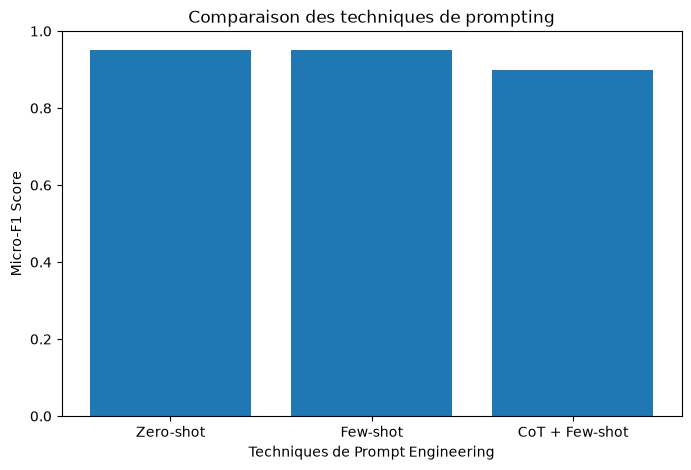

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Technique"],
    comparison["Micro-F1"]
)

plt.xlabel("Techniques de Prompt Engineering")
plt.ylabel("Micro-F1 Score")
plt.title("Comparaison des techniques de prompting")

plt.ylim(0, 1)
plt.show()


In [35]:

def create_examples(dataset, n=4, seed=42):

    # Garder des avis relativement courts
    pool = dataset[
        dataset["text"].str.len().between(50, 600)
    ]

    # Sélectionner n avis positifs
    positive_examples = pool[
        pool["sentiment"] == "positive"
    ].sample(n=n, random_state=seed)

    # Sélectionner n avis négatifs
    negative_examples = pool[
        pool["sentiment"] == "negative"
    ].sample(n=n, random_state=seed)

    # Regrouper les exemples
    examples = pd.concat([
        positive_examples,
        negative_examples
    ])

    # Mélanger leur ordre
    examples = examples.sample(
        frac=1,
        random_state=seed
    )

    return examples.reset_index(drop=True)


In [36]:

exemples_test = create_examples(
    examples_df,
    n=4,
    seed=42
)

print(exemples_test["sentiment"].value_counts())


sentiment
positive    4
negative    4
Name: count, dtype: int64


In [37]:

def create_prompt(system_message, examples):

    # Message système
    prompt = [
        {
            "role": "system",
            "content": system_message
        }
    ]

    # Ajouter chaque exemple au prompt
    for _, row in examples.iterrows():

        prompt.append({
            "role": "user",
            "content": (
                f"Classify this movie review:\n"
                f"```{row['text']}```"
            )
        })

        prompt.append({
            "role": "assistant",
            "content": row["sentiment"]
        })

    return prompt


In [38]:

from sklearn.metrics import f1_score

def evaluate_prompt(prompt, gold_df, model):

    predictions = []
    ground_truths = []

    # Parcourir les avis de référence
    for _, row in gold_df.iterrows():

        review = row["text"]
        true_sentiment = row["sentiment"]

        # Préparer le message utilisateur
        user_message = {
            "role": "user",
            "content": (
                f"Classify this movie review:\n"
                f"```{review}```"
            )
        }

        # Interroger le LLM
        response = model.invoke(
            prompt + [user_message]
        )

        # Extraire la prédiction
        prediction = response.content.strip().lower()

        # Vérifier le format
        if prediction not in ["positive", "negative"]:
            prediction = "unknown"

        predictions.append(prediction)
        ground_truths.append(true_sentiment)

    # Calculer le Micro-F1
    score = f1_score(
        ground_truths,
        predictions,
        average="micro"
    )

    return score


In [39]:

# Nombre de répétitions
num_eval_runs = 2

# Stocker les résultats
few_shot_performance = []
cot_few_shot_performance = []

for i in range(num_eval_runs):

    print(f"\n===== Expérience {i+1} =====")

    # Sélectionner de nouveaux exemples
    examples = create_examples(
        examples_df,
        n=4,
        seed=42+i
    )

    # Construire le prompt Few-shot
    new_few_shot_prompt = create_prompt(
        zero_shot_system_message,
        examples
    )

    # Construire le prompt CoT
    new_cot_prompt = create_prompt(
        cot_system_message,
        examples
    )

    # Évaluer le Few-shot
    few_score = evaluate_prompt(
        new_few_shot_prompt,
        gold_sample_df,
        llm
    )

    # Évaluer le CoT
    cot_score = evaluate_prompt(
        new_cot_prompt,
        gold_sample_df,
        llm
    )

    # Enregistrer les scores
    few_shot_performance.append(few_score)
    cot_few_shot_performance.append(cot_score)

    print("Few-shot Micro-F1 :", few_score)
    print("CoT Micro-F1 :", cot_score)



===== Expérience 1 =====
Few-shot Micro-F1 : 0.95
CoT Micro-F1 : 0.9

===== Expérience 2 =====
Few-shot Micro-F1 : 0.9
CoT Micro-F1 : 0.85


In [40]:

import numpy as np

results = pd.DataFrame({
    "Few-shot": few_shot_performance,
    "CoT + Few-shot": cot_few_shot_performance
})

display(results)

print("\nMoyenne des scores :")
print(results.mean())

print("\nÉcart-type des scores :")
print(results.std())


,Few-shot,CoT + Few-shot
0,0.95,0.90
1,0.90,0.85



Moyenne des scores :
Few-shot          0.925
CoT + Few-shot    0.875
dtype: float64

Écart-type des scores :
Few-shot          0.035355
CoT + Few-shot    0.035355
dtype: float64
